Generating record list for: 100
Generating record list for: 101
Generating record list for: 102
Generating record list for: 103
Generating record list for: 104
Generating record list for: 105
Generating record list for: 106
Generating record list for: 107
Generating record list for: 108
Generating record list for: 109
Generating record list for: 111
Generating record list for: 112
Generating record list for: 113
Generating record list for: 114
Generating record list for: 115
Generating record list for: 116
Generating record list for: 117
Generating record list for: 118
Generating record list for: 119
Generating record list for: 121
Generating record list for: 122
Generating record list for: 123
Generating record list for: 124
Generating record list for: 200
Generating record list for: 201
Generating record list for: 202
Generating record list for: 203
Generating record list for: 205
Generating record list for: 207
Generating record list for: 208
Generating record list for: 209
Generati

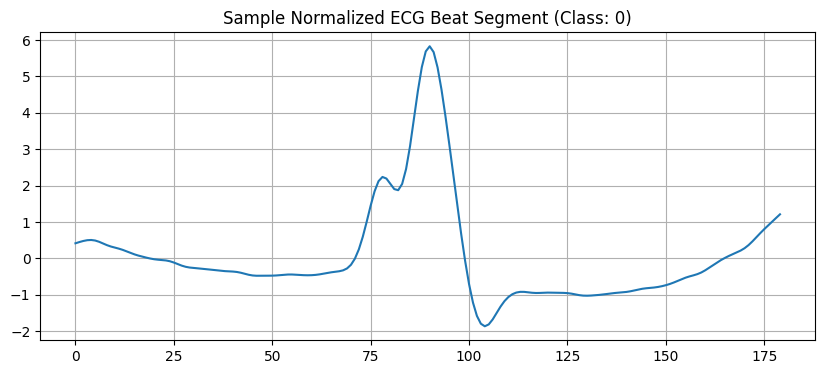


--- Training RNN Model ---


In [ ]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import signal
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, f1_score, precision_score, recall_score
from sklearn.utils import resample

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, TensorDataset

# Install wfdb if not available
try:
    import wfdb
except ImportError:
    !pip install wfdb
    import wfdb

# Set seeds for reproducibility
torch.manual_seed(42)
np.random.seed(42)

# ==========================================
# TASK 1 & 2: DATA ACQUISITION & PREPROCESSING
# ==========================================

# 1. Download database if not already present
data_dir = 'mitdb'
if not os.path.exists(data_dir):
    print("Downloading MIT-BIH Database...")
    wfdb.dl_database('mitdb', dl_dir=data_dir)

# List of records (excluding paced records: 102, 104, 107, 217)
all_records = [
    '100', '101', '103', '105', '106', '108', '109', '111', '112', '113',
    '114', '115', '116', '117', '118', '119', '121', '122', '123', '124',
    '200', '201', '202', '203', '205', '207', '208', '209', '210', '212',
    '213', '214', '215', '219', '220', '221', '222', '223', '228', '230',
    '231', '232', '233', '234'
]

# Mapping to AAMI categories
# N: Normal, Left/Right bundle branch block, etc.
# S: Supraventricular ectopic beat
# V: Ventricular ectopic beat
# F: Fusion beat
# Q: Unknown beat
aami_mapping = {
    'N': 0, 'L': 0, 'R': 0, 'e': 0, 'j': 0,        # N
    'A': 1, 'a': 1, 'J': 1, 'S': 1,                # S
    'V': 2, 'E': 2,                                # V
    'F': 3,                                        # F
    'P': -1, '/': -1, 'f': -1, 'U': -1, 'Q': 4,    # Q & Ignore non-beat/paced labels (-1)
}

def bandpass_filter(data, lowcut=0.5, highcut=40.0, fs=360.0, order=3):
    nyq = 0.5 * fs
    low = lowcut / nyq
    high = highcut / nyq
    b, a = signal.butter(order, [low, high], btype='band')
    return signal.filtfilt(b, a, data)

def load_and_preprocess_data(records, data_dir, win_size=180):
    X = []
    y = []
    patient_ids = []

    for rec_id in records:
        path = os.path.join(data_dir, rec_id)
        record = wfdb.rdrecord(path)
        annotation = wfdb.rdann(path, 'atr')

        # Use lead 0 (usually MLII)
        sig = record.p_signal[:, 0]
        filtered_sig = bandpass_filter(sig)

        # Standardize record signal
        filtered_sig = (filtered_sig - np.mean(filtered_sig)) / np.std(filtered_sig)

        peaks = annotation.sample
        labels = annotation.symbol

        half_win = win_size // 2
        for i, (peak, label) in enumerate(zip(peaks, labels)):
            if label in aami_mapping:
                mapped_label = aami_mapping[label]
                if mapped_label != -1: # Filter out non-beats
                    if peak - half_win >= 0 and peak + half_win < len(filtered_sig):
                        segment = filtered_sig[peak - half_win : peak + half_win]
                        X.append(segment)
                        y.append(mapped_label)
                        patient_ids.append(rec_id)

    return np.array(X), np.array(y), np.array(patient_ids)

print("Processing signals and segmenting beats...")
X_all, y_all, patient_all = load_and_preprocess_data(all_records, data_dir)

# Inter-patient Split to avoid data leakage
train_patients = ['100', '101', '103', '105', '106', '108', '109', '111', '112', '113', '114', '115', '116', '117', '118', '119', '121', '122', '123', '124', '200', '201', '202', '203', '205', '207', '208', '209', '210', '212']
test_patients = ['213', '214', '215', '219', '220', '221', '222', '223', '228', '230', '231', '232', '233', '234']

train_mask = np.isin(patient_all, train_patients)
test_mask = np.isin(patient_all, test_patients)

X_train_raw, y_train_raw = X_all[train_mask], y_all[train_mask]
X_test, y_test = X_all[test_mask], y_all[test_mask]

# Further split validation set from train set (inter-patient split preservation)
val_patients = train_patients[-6:]
train_patients_final = train_patients[:-6]

train_final_mask = np.isin(patient_all, train_patients_final)
val_mask = np.isin(patient_all, val_patients)

X_train, y_train = X_all[train_final_mask], y_all[train_final_mask]
X_val, y_val = X_all[val_mask], y_all[val_mask]

# Resolve Training Set Class Imbalance via Resampling
def balance_classes(X, y):
    df = pd.DataFrame(X)
    df['label'] = y
    max_size = df['label'].value_counts().max()

    lst = []
    for class_index, group in df.groupby('label'):
        lst.append(resample(group, replace=True, n_samples=max_size, random_state=42))

    df_balanced = pd.concat(lst)
    return df_balanced.iloc[:, :-1].values, df_balanced['label'].values

X_train, y_train = balance_classes(X_train, y_train)

print(f"Train samples: {X_train.shape[0]}, Val samples: {X_val.shape[0]}, Test samples: {X_test.shape[0]}")

# Plot Sample Beat
plt.figure(figsize=(10, 4))
plt.plot(X_train[0])
plt.title(f"Sample Normalized ECG Beat Segment (Class: {y_train[0]})")
plt.grid(True)
plt.show()

# Convert to PyTorch Dataloaders
batch_size = 64
train_loader = DataLoader(TensorDataset(torch.tensor(X_train, dtype=torch.float32).unsqueeze(-1), torch.tensor(y_train, dtype=torch.long)), batch_size=batch_size, shuffle=True)
val_loader = DataLoader(TensorDataset(torch.tensor(X_val, dtype=torch.float32).unsqueeze(-1), torch.tensor(y_val, dtype=torch.long)), batch_size=batch_size, shuffle=False)
test_loader = DataLoader(TensorDataset(torch.tensor(X_test, dtype=torch.float32).unsqueeze(-1), torch.tensor(y_test, dtype=torch.long)), batch_size=batch_size, shuffle=False)

# ==========================================
# TASK 3: MODEL CONFIGURATION AND TRAINING
# ==========================================

class RecurrentClassifier(nn.Module):
    def __init__(self, mode='LSTM', input_size=1, hidden_size=64, num_layers=2, num_classes=5):
        super(RecurrentClassifier, self).__init__()
        self.mode = mode
        self.hidden_size = hidden_size
        self.num_layers = num_layers

        if mode == 'RNN':
            self.rnn = nn.RNN(input_size, hidden_size, num_layers, batch_first=True)
        elif mode == 'LSTM':
            self.rnn = nn.LSTM(input_size, hidden_size, num_layers, batch_first=True)
        elif mode == 'GRU':
            self.rnn = nn.GRU(input_size, hidden_size, num_layers, batch_first=True)

        self.fc = nn.Linear(hidden_size, num_classes)

    def forward(self, x):
        out, _ = self.rnn(x)
        out = self.fc(out[:, -1, :])
        return out

def train_model(model, train_loader, val_loader, epochs=10, lr=0.001):
    device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
    model = model.to(device)
    criterion = nn.CrossEntropyLoss()
    optimizer = optim.Adam(model.parameters(), lr=lr)

    best_val_loss = float('inf')
    best_weights = None

    for epoch in range(epochs):
        model.train()
        train_loss = 0
        for inputs, targets in train_loader:
            inputs, targets = inputs.to(device), targets.to(device)
            optimizer.zero_grad()
            outputs = model(inputs)
            loss = criterion(outputs, targets)
            loss.backward()
            optimizer.step()
            train_loss += loss.item() * inputs.size(0)

        # Validation
        model.eval()
        val_loss = 0
        correct = 0
        total = 0
        with torch.no_grad():
            for inputs, targets in val_loader:
                inputs, targets = inputs.to(device), targets.to(device)
                outputs = model(inputs)
                loss = criterion(outputs, targets)
                val_loss += loss.item() * inputs.size(0)
                _, predicted = outputs.max(1)
                total += targets.size(0)
                correct += predicted.eq(targets).sum().item()

        train_loss /= len(train_loader.dataset)
        val_loss /= len(val_loader.dataset)
        val_acc = correct / total

        print(f"Epoch {epoch+1}/{epochs} - Train Loss: {train_loss:.4f} - Val Loss: {val_loss:.4f} - Val Acc: {val_acc:.4f}")

        # Early Stopping Logic
        if val_loss < best_val_loss:
            best_val_loss = val_loss
            best_weights = model.state_dict()

    model.load_state_dict(best_weights)
    return model

def evaluate_model(model, test_loader):
    device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
    model = model.to(device)
    model.eval()
    y_true = []
    y_pred = []
    with torch.no_grad():
        for inputs, targets in test_loader:
            inputs, targets = inputs.to(device), targets.to(device)
            outputs = model(inputs)
            _, predicted = outputs.max(1)
            y_true.extend(targets.cpu().numpy())
            y_pred.extend(predicted.cpu().numpy())
    return np.array(y_true), np.array(y_pred)

# Train RNN, LSTM, and GRU
models = {}
results = {}
architectures = ['RNN', 'LSTM', 'GRU']

for arch in architectures:
    print(f"\n--- Training {arch} Model ---")
    model = RecurrentClassifier(mode=arch)
    trained_model = train_model(model, train_loader, val_loader, epochs=8, lr=0.001)
    models[arch] = trained_model

    y_true, y_pred = evaluate_model(trained_model, test_loader)
    results[arch] = (y_true, y_pred)

# ==========================================
# COMPARISON AND METRICS PLOTTING
# ==========================================

for arch in architectures:
    y_true, y_pred = results[arch]
    print(f"\n================ {arch} Classification Report ================")
    print(classification_report(y_true, y_pred, target_names=['N', 'S', 'V', 'F', 'Q'], zero_division=0))
    print(f"Confusion Matrix for {arch}:")
    print(confusion_matrix(y_true, y_pred))
